In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu
housing_data = pd.read_csv(
    "data/HousingPrices-Amsterdam-August-2021.csv",
    index_col=0
)

print("Kích thước dữ liệu:", housing_data.shape)
display(housing_data.head())

Kích thước dữ liệu: (924, 7)


,Address,Zip,Price,Area,Room,Lon,Lat
1,"Blasiusstraat 8 2, Amsterdam",1091 CR,685000.0,64,3,4.907736,52.356157
2,"Kromme Leimuidenstraat 13 H, Amsterdam",1059 EL,475000.0,60,3,4.850476,52.348586
3,"Zaaiersweg 11 A, Amsterdam",1097 SM,850000.0,109,4,4.944774,52.343782
4,"Tenerifestraat 40, Amsterdam",1060 TH,580000.0,128,6,4.789928,52.343712
5,"Winterjanpad 21, Amsterdam",1036 KN,720000.0,138,5,4.902503,52.410538


In [2]:
# Chọn các cột theo yêu cầu của lab
housing_data = housing_data[["Zip", "Price", "Area", "Room"]].copy()

print("Kích thước sau khi chọn cột:", housing_data.shape)

print("\nKiểu dữ liệu:")
print(housing_data.dtypes)

print("\nSố giá trị thiếu:")
print(housing_data.isna().sum())

print("\nSố dòng trùng hoàn toàn:", housing_data.duplicated().sum())
print("Số giá trị Price <= 0:", (housing_data["Price"] <= 0).sum())
print("Số giá trị Area <= 0:", (housing_data["Area"] <= 0).sum())

display(housing_data.head())

Kích thước sau khi chọn cột: (924, 4)

Kiểu dữ liệu:
Zip       object
Price    float64
Area       int64
Room       int64
dtype: object

Số giá trị thiếu:
Zip      0
Price    4
Area     0
Room     0
dtype: int64

Số dòng trùng hoàn toàn: 6
Số giá trị Price <= 0: 0
Số giá trị Area <= 0: 0


,Zip,Price,Area,Room
1,1091 CR,685000.0,64,3
2,1059 EL,475000.0,60,3
3,1097 SM,850000.0,109,4
4,1060 TH,580000.0,128,6
5,1036 KN,720000.0,138,5


In [3]:
# Tạo bản dữ liệu có đầy đủ giá
housing_clean = housing_data.dropna(subset=["Price"]).copy()

# Tính giá trên mỗi mét vuông
housing_clean["PriceperSqm"] = (
    housing_clean["Price"] / housing_clean["Area"]
)

# Sắp xếp theo giá nhà giảm dần
housing_sorted = housing_clean.sort_values(
    by="Price",
    ascending=False
)

print("Số dòng ban đầu:", len(housing_data))
print("Số dòng thiếu giá đã loại:", len(housing_data) - len(housing_clean))
print("Số dòng dùng để phân tích:", len(housing_clean))

display(housing_sorted.head(10))

Số dòng ban đầu: 924
Số dòng thiếu giá đã loại: 4
Số dòng dùng để phân tích: 920


,Zip,Price,Area,Room,PriceperSqm
196,1017 EL,5950000.0,394,10,15101.522843
838,1075 AH,5850000.0,480,14,12187.500000
306,1016 AE,4900000.0,623,13,7865.168539
104,1017 ZP,4550000.0,497,13,9154.929577
180,1012 JS,4495000.0,178,5,25252.808989
34,1054 GJ,3925000.0,319,7,12304.075235
302,1031 KV,3680000.0,374,4,9839.572193
335,1015 AG,3500000.0,348,8,10057.471264
277,1075 BM,3500000.0,374,7,9358.288770
265,1076 XP,2750000.0,309,8,8899.676375


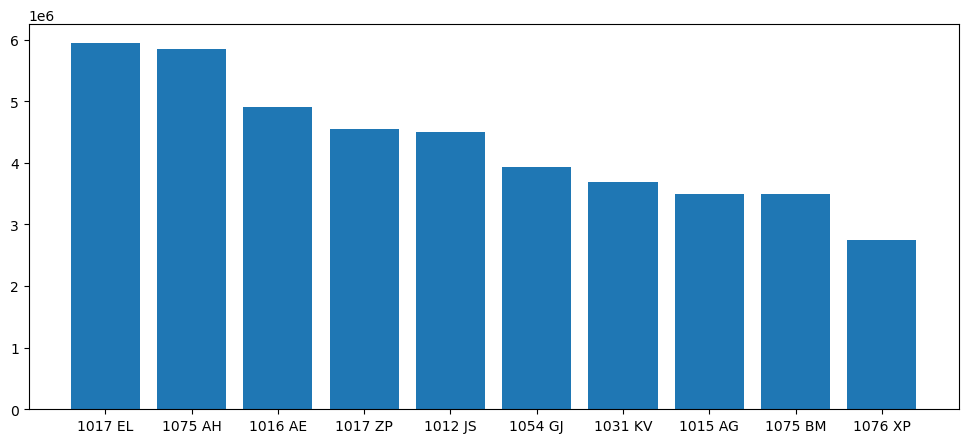

In [4]:
# Lấy 10 căn có giá nhà cao nhất
housing_top10 = housing_sorted.head(10).copy()

plt.figure(figsize=(12, 5))
plt.bar(housing_top10["Zip"], housing_top10["Price"])

plt.show()

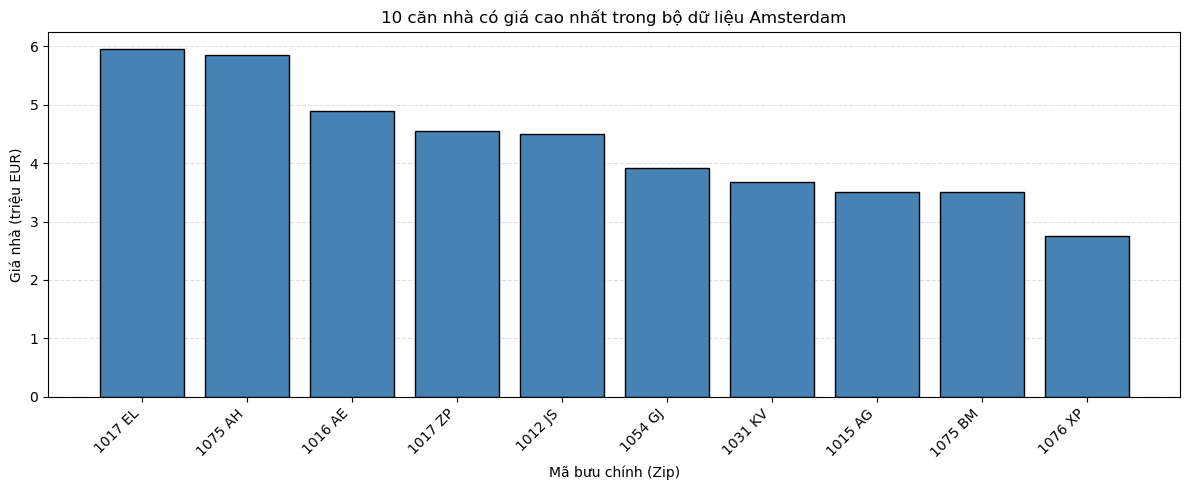

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    housing_top10["Zip"],
    housing_top10["Price"] / 1_000_000,
    color="steelblue",
    edgecolor="black"
)

ax.set_title("10 căn nhà có giá cao nhất trong bộ dữ liệu Amsterdam")
ax.set_xlabel("Mã bưu chính (Zip)")
ax.set_ylabel("Giá nhà (triệu EUR)")

plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

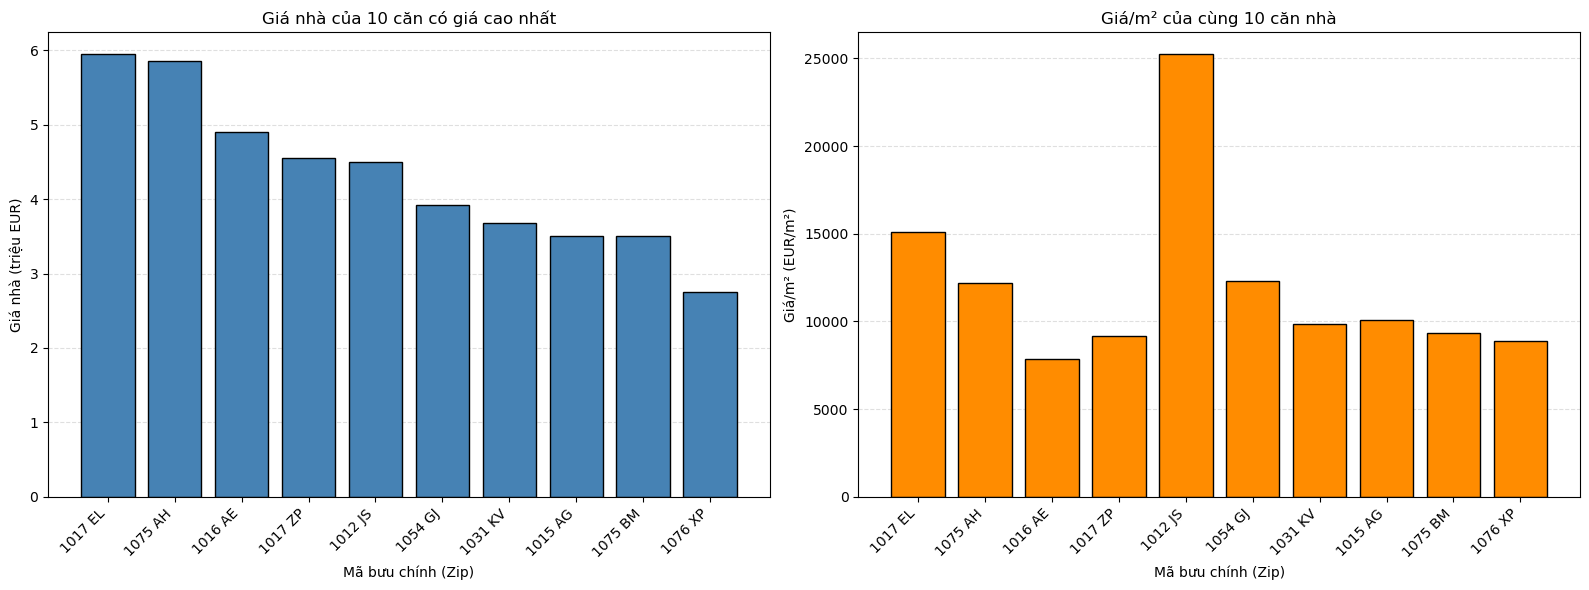

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Biểu đồ bên trái: giá nhà
axes[0].bar(
    housing_top10["Zip"],
    housing_top10["Price"] / 1_000_000,
    color="steelblue",
    edgecolor="black"
)
axes[0].set_title("Giá nhà của 10 căn có giá cao nhất")
axes[0].set_ylabel("Giá nhà (triệu EUR)")

# Biểu đồ bên phải: giá trên mỗi mét vuông
axes[1].bar(
    housing_top10["Zip"],
    housing_top10["PriceperSqm"],
    color="darkorange",
    edgecolor="black"
)
axes[1].set_title("Giá/m² của cùng 10 căn nhà")
axes[1].set_ylabel("Giá/m² (EUR/m²)")

# Định dạng chung
for ax in axes:
    ax.set_xlabel("Mã bưu chính (Zip)")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

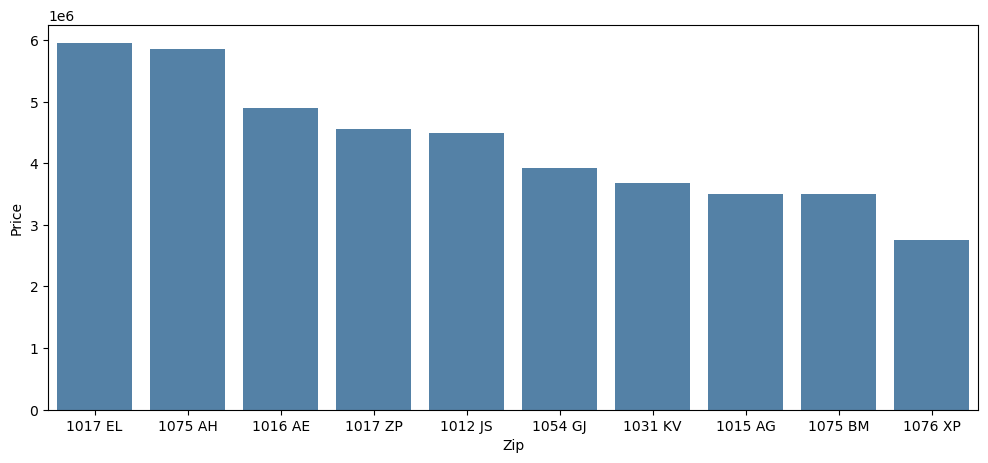

In [7]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=housing_top10,
    x="Zip",
    y="Price",
    order=housing_top10["Zip"].tolist(),
    color="steelblue"
)

plt.show()

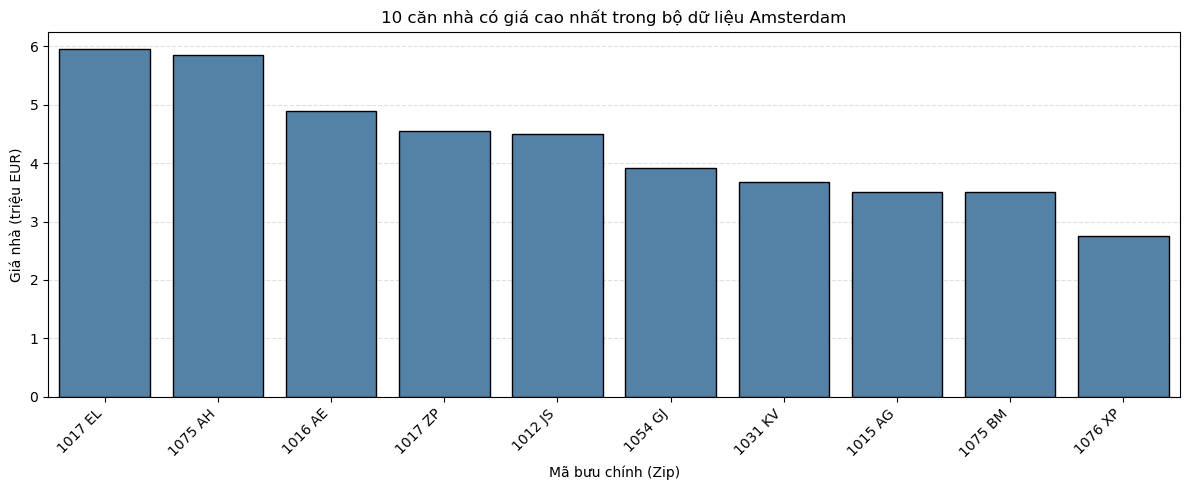

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(
    x=housing_top10["Zip"],
    y=housing_top10["Price"] / 1_000_000,
    order=housing_top10["Zip"].tolist(),
    color="steelblue",
    edgecolor="black",
    ax=ax
)

ax.set_title("10 căn nhà có giá cao nhất trong bộ dữ liệu Amsterdam")
ax.set_xlabel("Mã bưu chính (Zip)")
ax.set_ylabel("Giá nhà (triệu EUR)")

plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

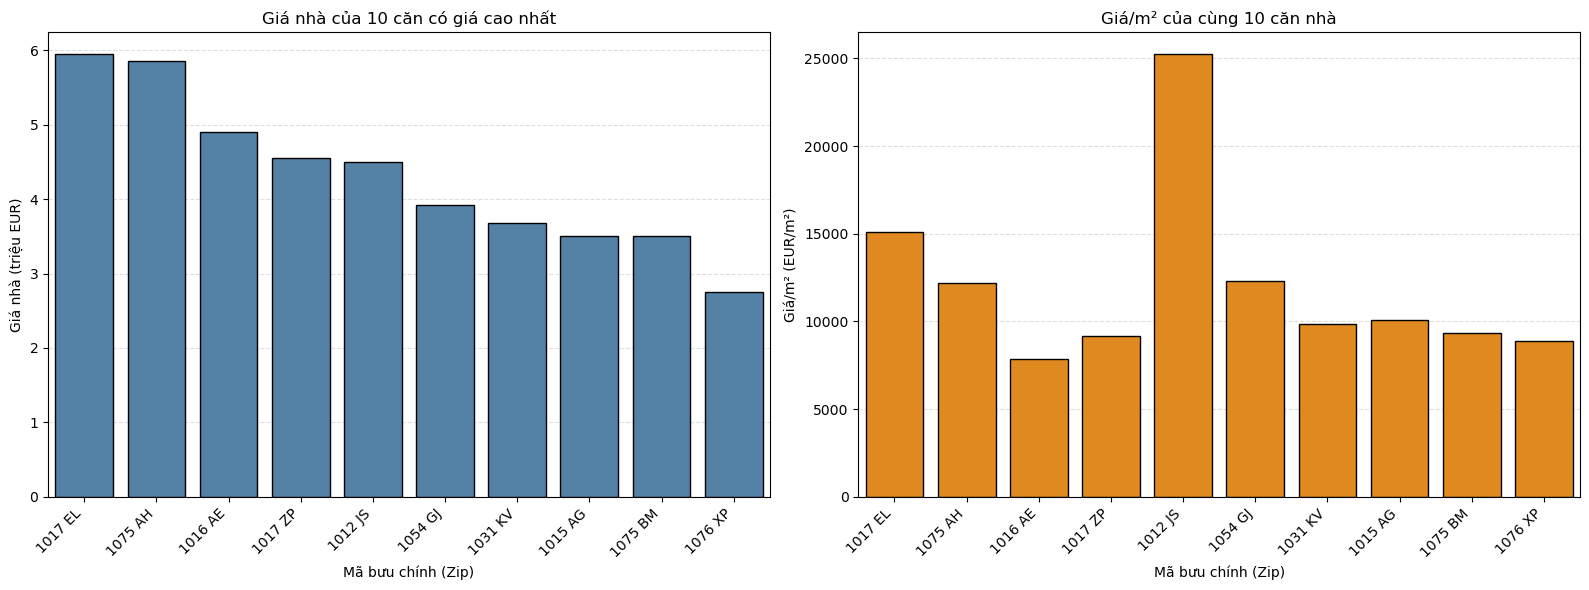

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

zip_order = housing_top10["Zip"].tolist()

# Bên trái: giá nhà
sns.barplot(
    x=housing_top10["Zip"],
    y=housing_top10["Price"] / 1_000_000,
    order=zip_order,
    color="steelblue",
    edgecolor="black",
    ax=axes[0]
)
axes[0].set_title("Giá nhà của 10 căn có giá cao nhất")
axes[0].set_ylabel("Giá nhà (triệu EUR)")

# Bên phải: giá trên mỗi mét vuông
sns.barplot(
    data=housing_top10,
    x="Zip",
    y="PriceperSqm",
    order=zip_order,
    color="darkorange",
    edgecolor="black",
    ax=axes[1]
)
axes[1].set_title("Giá/m² của cùng 10 căn nhà")
axes[1].set_ylabel("Giá/m² (EUR/m²)")

# Định dạng chung
for ax in axes:
    ax.set_xlabel("Mã bưu chính (Zip)")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Nhận xét

- Bộ dữ liệu ban đầu có 924 căn nhà. Sau khi loại 4 dòng thiếu giá,
  còn 920 dòng dùng để phân tích. Giá trên mỗi mét vuông được tính
  bằng giá nhà chia cho diện tích.
- Trong 10 căn có giá nhà cao nhất, căn mang mã bưu chính 1017 EL
  có giá cao nhất là 5,95 triệu EUR.
- Trong cùng nhóm 10 căn này, căn mang mã bưu chính 1012 JS có
  giá/m² cao nhất, khoảng 25.253 EUR/m², dù tổng giá đứng thứ 5.
  Điều này cho thấy thứ tự theo tổng giá có thể khác thứ tự theo giá/m².
- Biểu đồ giá/m² sử dụng cùng 10 căn được chọn theo tổng giá,
  không phải 10 căn có giá/m² cao nhất trong toàn bộ dữ liệu.
- Matplotlib và Seaborn thể hiện kết quả nhất quán. Việc bổ sung
  tiêu đề, tên trục, đơn vị và xoay nhãn giúp biểu đồ dễ đọc hơn.
- Các nhận xét trên chỉ áp dụng cho nhóm căn nhà được chọn
  trong bộ dữ liệu, chưa đại diện cho toàn bộ thị trường Amsterdam.